Sensor         Mean        Std       Cp      Cpk  Rating
X163        4793.31    6550.27     1.00     1.00  Marginal (≥1.0)
X162        4065.00    4236.85     1.00     1.00  Marginal (≥1.0)
X298        2340.88    3225.32     1.00     1.00  Marginal (≥1.0)
X25         -298.32    2900.85     1.00     1.00  Marginal (≥1.0)
X297        1878.36    1974.00     1.00     1.00  Marginal (≥1.0)

Note: Specs assumed as mean ± 3σ (no real product specs in SECOM dataset).
In practice, specs come from the product definition.


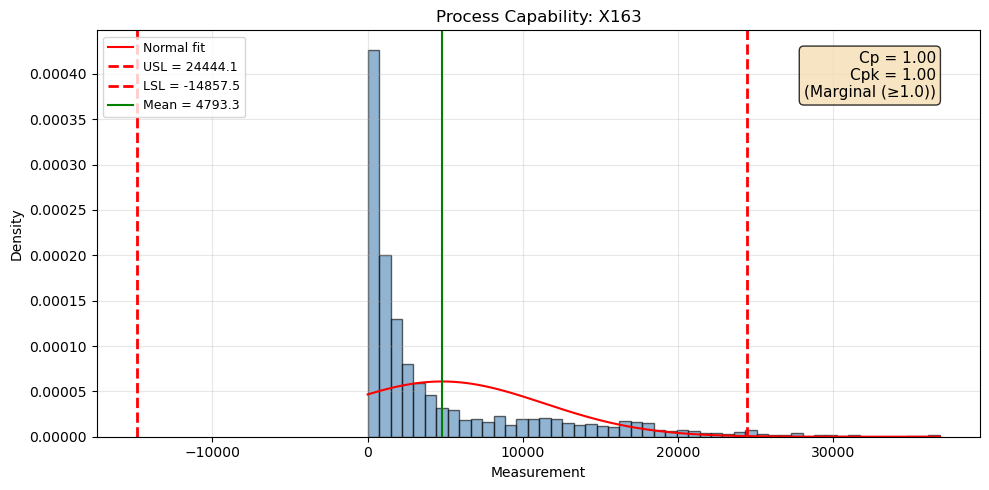

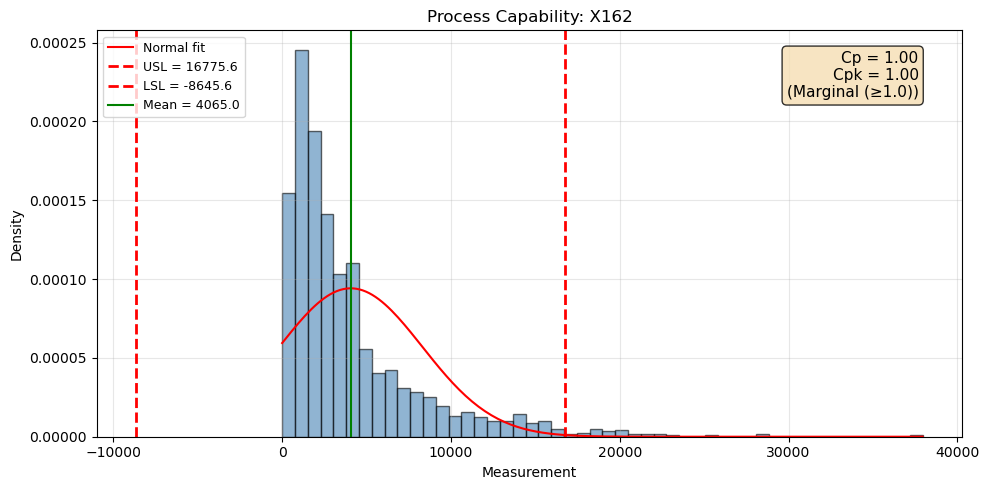


✅ Capability analysis complete. Summary saved.


In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "C:/Users/sharanu.ganji/secom-yield-dashboard/src")
from capability import compute_cp_cpk, interpret_cpk, plot_capability

DATA_DIR = "C:/Users/sharanu.ganji/secom-yield-dashboard/data"
os.makedirs(os.path.join(DATA_DIR, "capability_plots"), exist_ok=True)

# Load
df = pd.read_csv(os.path.join(DATA_DIR, "secom_cleaned.csv"), parse_dates=["Time"])
df = df.sort_values("Time").reset_index(drop=True)

sensor_cols = [c for c in df.columns if c.startswith("X")]
top_sensors = df[sensor_cols].var().nlargest(5).index.tolist()

# Since SECOM has no real spec limits, we ASSUME specs based on data:
# USL/LSL = mean ± 3*std (i.e., the "spec" is what the process naturally produces)
# This is a common exercise when no real specs are available.
# In a real fab, these would come from the product spec sheet.

print("=" * 60)
print(f"{'Sensor':<8} {'Mean':>10} {'Std':>10} {'Cp':>8} {'Cpk':>8}  Rating")
print("=" * 60)

results = []
for sensor in top_sensors:
    values = df[sensor].values
    mean, std = values.mean(), values.std(ddof=1)
    usl = mean + 3 * std
    lsl = mean - 3 * std
    stats = compute_cp_cpk(values, usl, lsl)
    results.append({"sensor": sensor, **stats})
    print(f"{sensor:<8} {mean:>10.2f} {std:>10.2f} {stats['cp']:>8.2f} {stats['cpk']:>8.2f}  {interpret_cpk(stats['cpk'])}")

print("=" * 60)
print("\nNote: Specs assumed as mean ± 3σ (no real product specs in SECOM dataset).")
print("In practice, specs come from the product definition.")

# Plot capability for top 2 sensors
for sensor in top_sensors[:2]:
    values = df[sensor].values
    mean, std = values.mean(), values.std(ddof=1)
    usl, lsl = mean + 3*std, mean - 3*std
    stats = compute_cp_cpk(values, usl, lsl)
    plot_capability(values, stats,
                    title=f"Process Capability: {sensor}",
                    save_path=os.path.join(DATA_DIR, "capability_plots", f"capability_{sensor}.png"))

# Summary table as DataFrame
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(DATA_DIR, "capability_plots", "capability_summary.csv"), index=False)
print(f"\n✅ Capability analysis complete. Summary saved.")   